# PixPay — Auditoria de Qualidade dos Dados

**Escopo:** valores ausentes, duplicatas e inconsistências de formato nas colunas categóricas de `data/clientes_pixpay.csv`.

**Regras seguindo o `CLAUDE.md`:**
- Este notebook é **somente diagnóstico**: nenhuma linha é descartada ou alterada. Qualquer limpeza será proposta e só aplicada após confirmação.
- O CSV é lido tudo como texto (`dtype=str`) e sem conversão automática de nulos, para que o pandas não esconda problemas de formato (ex.: `"n/a"` virando `NaN`, ou `"R$ 19,90"` quebrando a conversão numérica).
- Funções retornam `dict` ou `DataFrame`; quem exibe é a célula que as chama.

In [1]:
import re
import unicodedata
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# Funciona tanto rodando de notebooks/ quanto da raiz do projeto
CAMINHO_CSV = next(p for p in (Path("../data/clientes_pixpay.csv"), Path("data/clientes_pixpay.csv")) if p.exists())

# Tokens que costumam representar "ausente" disfarçado de valor
TOKENS_AUSENTE = {"", "nan", "null", "none", "n/a", "na", "-", "--", "?", "nd", "s/i"}

COLUNAS_NUMERICAS = ["notificacoes_7d", "transacoes_30d", "ticket_medio_30d", "tempo_resposta_chamado_h"]

## 1. Carga e validação de tipos

In [2]:
def carregar_csv(caminho):
    """Lê o CSV 100% como texto, sem converter nulos.

    Decisão: dtype=str + keep_default_na=False. Assim "" continua "" e tokens como
    "N/A" continuam visíveis, em vez de o pandas decidir sozinho o que é nulo.
    Encoding utf-8 explícito (arquivo validado como UTF-8).
    """
    return pd.read_csv(caminho, dtype=str, keep_default_na=False, encoding="utf-8")


def validar_tipos(df):
    """Para cada coluna: quantos valores são não vazios e quantos convertem para o tipo esperado."""
    esperado = {
        "notificacoes_7d": "numérico", "transacoes_30d": "numérico",
        "ticket_medio_30d": "numérico", "tempo_resposta_chamado_h": "numérico",
    }
    linhas = []
    for col in df.columns:
        nao_vazios = df[col].str.strip().ne("")
        if col in esperado:
            conv = pd.to_numeric(df[col].where(nao_vazios), errors="coerce")
            falhas = int((nao_vazios & conv.isna()).sum())
            linhas.append({"coluna": col, "tipo_esperado": "numérico", "nao_vazios": int(nao_vazios.sum()),
                           "falham_conversao": falhas})
        else:
            linhas.append({"coluna": col, "tipo_esperado": "texto/categórico/data (ver seções 4-5)",
                           "nao_vazios": int(nao_vazios.sum()), "falham_conversao": None})
    return pd.DataFrame(linhas)


df = carregar_csv(CAMINHO_CSV)
resultado_tipos = validar_tipos(df)
{"linhas": df.shape[0], "colunas": df.shape[1]}

{'linhas': 10016, 'colunas': 15}

In [3]:
resultado_tipos

,coluna,tipo_esperado,nao_vazios,falham_conversao
0,cliente_id,texto/categórico/data (ver seções 4-5),10016,NaN
1,nome,texto/categórico/data (ver seções 4-5),10016,NaN
2,cpf,texto/categórico/data (ver seções 4-5),10016,NaN
3,data_cadastro,texto/categórico/data (ver seções 4-5),10016,NaN
4,data_cancelamento,texto/categórico/data (ver seções 4-5),1353,NaN
5,cidade,texto/categórico/data (ver seções 4-5),10016,NaN
6,estado,texto/categórico/data (ver seções 4-5),10016,NaN
7,plano,texto/categórico/data (ver seções 4-5),10016,NaN
8,valor_mensalidade,texto/categórico/data (ver seções 4-5),10016,NaN
9,notificacoes_7d,numérico,10016,0.0


## 2. Valores ausentes

Além de `""`, procuramos tokens que representam ausência disfarçada (`N/A`, `-`, `null`...).
Depois, em vez de apenas contar, **testamos se a ausência faz sentido** (hipótese: ausência estrutural, ex.: `data_cancelamento` só existe para quem cancelou) ou se é suspeita (ausência que parece depender do desfecho).

In [4]:
def auditar_ausentes(df):
    """Contagem de ausentes por coluna, separando vazio real de token-placeholder."""
    norm = df.apply(lambda s: s.str.strip().str.casefold())
    vazios = (norm == "").sum()
    placeholders = norm.isin(TOKENS_AUSENTE - {""}).sum()
    out = pd.DataFrame({"vazios": vazios, "placeholders": placeholders})
    out["total_ausente"] = out["vazios"] + out["placeholders"]
    out["pct_ausente"] = (out["total_ausente"] / len(df) * 100).round(2)
    return out.sort_values("total_ausente", ascending=False)


ausentes = auditar_ausentes(df)
ausentes

,vazios,placeholders,total_ausente,pct_ausente
data_cancelamento,8663,0,8663,86.49
tempo_resposta_chamado_h,7489,0,7489,74.77
transacoes_30d,1216,0,1216,12.14
cliente_id,0,0,0,0.00
nome,0,0,0,0.00
cpf,0,0,0,0.00
data_cadastro,0,0,0,0.00
cidade,0,0,0,0.00
estado,0,0,0,0.00
plano,0,0,0,0.00


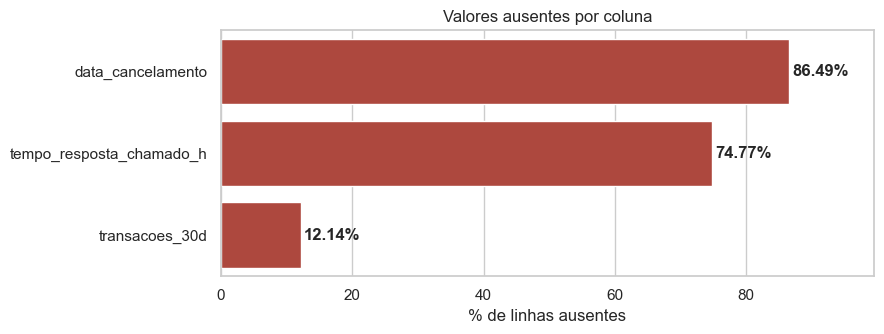

In [5]:
def grafico_ausentes(ausentes):
    dados = ausentes[ausentes["total_ausente"] > 0].reset_index(names="coluna")
    fig, ax = plt.subplots(figsize=(9, 3.5))
    sns.barplot(data=dados, y="coluna", x="pct_ausente", color="#c0392b", ax=ax)
    for i, v in enumerate(dados["pct_ausente"]):
        ax.text(v + 0.5, i, f"{v:.2f}%", va="center", fontweight="bold")
    ax.set_xlim(0, max(dados["pct_ausente"]) * 1.15)
    ax.set_xlabel("% de linhas ausentes")
    ax.set_ylabel("")
    ax.set_title("Valores ausentes por coluna")
    plt.tight_layout()
    return fig


fig_ausentes = grafico_ausentes(ausentes)
plt.show()

### 2.1 A ausência é estrutural ou suspeita?

Três hipóteses testáveis:
1. `data_cancelamento` ausente ⇔ `churn_30d == False` (ausência esperada).
2. `tempo_resposta_chamado_h` ausente ⇔ cliente não abriu chamado (ausência esperada).
3. `transacoes_30d` ausente **não** deveria ter motivo estrutural. Se ela se concentrar em quem deu churn, o ausente carrega informação e **não pode ser imputado/descartado às cegas**.

In [6]:
def normalizar_booleano(serie):
    """Mapeia true/false/sim/não (qualquer caixa/acento) para bool. Valor desconhecido vira NA."""
    mapa = {"true": True, "false": False, "sim": True, "nao": False}
    chave = serie.map(lambda x: sem_acento(x).strip().casefold())
    return chave.map(mapa).astype("boolean")


def sem_acento(texto):
    return unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")


def cruzar_ausencia(df):
    """Tabelas cruzando ausência com o evento que deveria explicá-la."""
    churn = normalizar_booleano(df["churn_30d"])
    chamado = normalizar_booleano(df["abriu_chamado"])
    aus = lambda col: df[col].str.strip().eq("")
    return {
        "data_cancelamento_vs_churn": pd.crosstab(aus("data_cancelamento").rename("data_cancelamento_vazia"), churn.rename("churn_30d")),
        "tempo_resposta_vs_chamado": pd.crosstab(aus("tempo_resposta_chamado_h").rename("tempo_resposta_vazio"), chamado.rename("abriu_chamado")),
        "transacoes_vs_churn": pd.crosstab(aus("transacoes_30d").rename("transacoes_vazia"), churn.rename("churn_30d")),
        "taxa_churn_por_transacoes_ausente": (
            churn.groupby(aus("transacoes_30d").rename("transacoes_vazia")).mean().mul(100).round(2).rename("churn_%")
        ).to_frame(),
    }


cruz = cruzar_ausencia(df)
for nome, tabela in cruz.items():
    print(f"--- {nome}")
    display(tabela)

--- data_cancelamento_vs_churn


churn_30d,False,True
data_cancelamento_vazia,,
False,0,1353
True,8663,0


--- tempo_resposta_vs_chamado


abriu_chamado,False,True
tempo_resposta_vazio,,
False,0,2527
True,7489,0


--- transacoes_vs_churn


churn_30d,False,True
transacoes_vazia,,
False,7599,1201
True,1064,152


--- taxa_churn_por_transacoes_ausente


,churn_%
transacoes_vazia,
False,13.65
True,12.5


## 3. Duplicatas

In [7]:
def auditar_duplicatas(df):
    """Duplicatas em 3 níveis: linha inteira, cliente_id e CPF.

    Para cada cliente_id repetido, conta em quantas colunas as cópias divergem:
    0 = cópia exata; >0 = registros conflitantes (precisa decidir qual vale).
    """
    exatas = df[df.duplicated(keep=False)]

    ids_rep = df[df["cliente_id"].duplicated(keep=False)].sort_values("cliente_id")
    divergencia = (
        ids_rep.groupby("cliente_id")
        .agg(lambda s: s.nunique())
        .gt(1)
        .sum(axis=1)
        .rename("colunas_divergentes")
        .to_frame()
        .join(ids_rep.groupby("cliente_id").size().rename("n_copias"))
    )

    cpf_ok = df[df["cpf"].str.strip().ne("")].copy()
    cpf_ok["cpf_digitos"] = cpf_ok["cpf"].str.replace(r"\D", "", regex=True)
    cpf_rep = cpf_ok[cpf_ok["cpf_digitos"].duplicated(keep=False)].sort_values("cpf_digitos")

    return {
        "resumo": pd.DataFrame({
            "metrica": ["linhas totais", "cliente_id únicos", "linhas excedentes por cliente_id",
                        "linhas 100% idênticas (excedentes)", "ids repetidos", "CPFs (só dígitos) repetidos"],
            "valor": [len(df), df["cliente_id"].nunique(), int(df["cliente_id"].duplicated().sum()),
                      int(df.duplicated().sum()), ids_rep["cliente_id"].nunique(), cpf_rep["cpf_digitos"].nunique()],
        }),
        "divergencia_por_id": divergencia.sort_values("colunas_divergentes", ascending=False),
        "linhas_id_repetido": ids_rep,
        "linhas_cpf_repetido": cpf_rep,
        "linhas_exatas": exatas,
    }


dups = auditar_duplicatas(df)
dups["resumo"]

,metrica,valor
0,linhas totais,10016
1,cliente_id únicos,10000
2,linhas excedentes por cliente_id,16
3,linhas 100% idênticas (excedentes),1
4,ids repetidos,16
5,CPFs (só dígitos) repetidos,16


In [8]:
dups["divergencia_por_id"]

,colunas_divergentes,n_copias
cliente_id,,
CLI004058,4,2
CLI006110,3,2
CLI008794,3,2
CLI000327,2,2
CLI000427,2,2
CLI001050,2,2
CLI001658,2,2
CLI002415,2,2
CLI002934,2,2


In [9]:
# Quais colunas divergem entre cópias do mesmo cliente_id?
def colunas_que_divergem(linhas_id_repetido):
    contagem = {}
    for _, grupo in linhas_id_repetido.groupby("cliente_id"):
        for col in grupo.columns:
            if grupo[col].nunique() > 1:
                contagem[col] = contagem.get(col, 0) + 1
    return pd.Series(contagem, name="ids_onde_diverge").sort_values(ascending=False).to_frame()


colunas_que_divergem(dups["linhas_id_repetido"])

,ids_onde_diverge
data_cadastro,9
valor_mensalidade,9
cpf,8
nome,3
abriu_chamado,2
plano,1


In [10]:
dups["linhas_id_repetido"]

,cliente_id,nome,cpf,data_cadastro,data_cancelamento,cidade,estado,plano,valor_mensalidade,notificacoes_7d,transacoes_30d,ticket_medio_30d,abriu_chamado,tempo_resposta_chamado_h,churn_30d
8587,CLI000327,Larissa Pinto,XXXXXXXXXXX,26/02/2025,,São Luís,MA,Premium,"R$ 49,90",10,5.0,87.23,False,,False
3421,CLI000327,Larissa Pinto,XXX.XXX.XXX-XX,26/02/2025,,São Luís,MA,Premium,"R$ 49,90",10,5.0,87.23,False,,False
6006,CLI000427,Ricardo Pinto,XXX.XXX.XXX-XX,2024-09-18,,Osasco,SP,Premium,49.90,8,40.0,30.76,True,18.6,False
3308,CLI000427,Ricardo Pinto,XXXXXXXXXXX,18-09-24,,Osasco,SP,Premium,49.90,8,40.0,30.76,True,18.6,False
4362,CLI001050,João Rodrigues,XXX.XXX.XXX-XX,18/08/2024,,Contagem,MG,Básico,19.90,4,15.0,77.54,False,,False
8245,CLI001050,João Rodrigues,XXX.XXX.XXX-XX,18/08/2024,,Contagem,MG,Básico,"R$ 19,90",4,15.0,77.54,False,,False
8225,CLI001658,Diego Ribeiro,XXXXXXXXXXX,26/11/2025,,Cajazeiras,PB,Básico,"19,90",12,13.0,775393.49,False,,False
4689,CLI001658,Diego Ribeiro,XXXXXXXXXXX,26/11/2025,,Cajazeiras,PB,Básico,19.90,12,13.0,775393.49,não,,False
780,CLI001958,Maria Almeida,XXX.XXX.XXX-XX,28/10/2025,,Uberlândia,MG,Básico,"19,90",8,34.0,90.3,False,,False
1890,CLI001958,Maria Almeida,XXX.XXX.XXX-XX,28/10/2025,,Uberlândia,MG,Básico,"19,90",8,34.0,90.3,False,,False


In [11]:
# CPF repetido: é o mesmo cliente (mesmo id) ou pessoas/ids diferentes com o mesmo CPF?
dups["linhas_cpf_repetido"][["cliente_id", "nome", "cpf", "data_cadastro", "plano", "churn_30d"]]

,cliente_id,nome,cpf,data_cadastro,plano,churn_30d
4265,CLI004058,Vanessa Almeida,XXXXXXXXXXX,2026-01-15,Premium,False
3004,CLI004058,Vanessa Almeida,XXX.XXX.XXX-XX,15/01/2026,Premium,False
8558,CLI008794,Amanda Gomes,XXX.XXX.XXX-XX,2024-04-26,Básico,False
4000,CLI008794,Amanda Gomes,XXXXXXXXXXX,26-04-24,Básico,False
1520,CLI008476,Eduardo Ribeiro,XXX.XXX.XXX-XX,08-04-24,Premium,False
1781,CLI008476,Eduardo Ribeiro,XXX.XXX.XXX-XX,08-04-24,Premium,False
7782,CLI002934,Tatiane Almeida,XXX.XXX.XXX-XX,10/08/2025,Premium,False
3825,CLI002934,TATIANE ALMEIDA,XXX.XXX.XXX-XX,2025-08-10,Premium,False
9320,CLI002262,Rafaela Marques,XXX.XXX.XXX-XX,19/07/2025,Premium,False
7013,CLI002262,Rafaela Marques,XXX.XXX.XXX-XX,19/07/2025,Premium,False


## 4. Inconsistências de formato — colunas categóricas

Estratégia: para cada coluna, listar **todas as grafias existentes**, propor uma forma canônica (`valor_proposto`) e sinalizar o que **não** conseguimos mapear. A proposta é só um mapeamento para revisão; **os dados não foram alterados**.

In [12]:
UF_POR_NOME = {
    "acre": "AC", "alagoas": "AL", "amapa": "AP", "amazonas": "AM", "bahia": "BA", "ceara": "CE",
    "distrito federal": "DF", "espirito santo": "ES", "goias": "GO", "maranhao": "MA",
    "mato grosso": "MT", "mato grosso do sul": "MS", "minas gerais": "MG", "para": "PA",
    "paraiba": "PB", "parana": "PR", "pernambuco": "PE", "piaui": "PI", "rio de janeiro": "RJ",
    "rio grande do norte": "RN", "rio grande do sul": "RS", "rondonia": "RO", "roraima": "RR",
    "santa catarina": "SC", "sao paulo": "SP", "sergipe": "SE", "tocantins": "TO",
}
PLANO_CANONICO = {
    "basico": "Básico", "basic": "Básico",
    "premium": "Premium", "premim": "Premium", "premiun": "Premium",
}
UFS_VALIDAS = set(UF_POR_NOME.values())


def chave(texto):
    """Chave de comparação: sem acento, sem espaços nas pontas, minúscula."""
    return sem_acento(texto).strip().casefold()


def propor_normalizacao(serie, mapa_canonico):
    """Tabela grafia -> contagem -> valor proposto. valor_proposto=NaN quando não há mapeamento."""
    tabela = serie.value_counts().rename_axis("grafia_original").reset_index(name="n")
    tabela["grafia_repr"] = tabela["grafia_original"].map(repr)  # repr deixa visíveis espaços nas pontas
    tabela["valor_proposto"] = tabela["grafia_original"].map(lambda v: mapa_canonico.get(chave(v)))
    return tabela[["grafia_repr", "n", "valor_proposto"]]


def mapa_estado():
    # aceita a própria sigla (qualquer caixa) e o nome por extenso
    return {**UF_POR_NOME, **{uf.casefold(): uf for uf in UFS_VALIDAS}}


tab_plano = propor_normalizacao(df["plano"], PLANO_CANONICO)
tab_plano

,grafia_repr,n,valor_proposto
0,'Básico',5698,Básico
1,'Premium',3818,Premium
2,'BASICO',62,Básico
3,'BÁSICO',56,Básico
4,'Básico ',55,Básico
5,'básico',49,Básico
6,'basic',44,Básico
7,'PREMIUM',41,Premium
8,'Basico',39,Básico
9,'premim',36,Premium


In [13]:
resumo_plano = (
    tab_plano.assign(valor_proposto=tab_plano["valor_proposto"].fillna("(sem mapeamento)"))
    .groupby("valor_proposto")["n"].agg(["sum", "count"]).rename(columns={"sum": "linhas", "count": "grafias_distintas"})
)
resumo_plano

,linhas,grafias_distintas
valor_proposto,,
Básico,6003,7
Premium,4013,7


In [14]:
tab_estado = propor_normalizacao(df["estado"], mapa_estado())
tab_estado[tab_estado["grafia_repr"].map(lambda r: r.strip("'") not in UFS_VALIDAS)]

,grafia_repr,n,valor_proposto
23,'Minas Gerais',4,MG
24,'Paraná',3,PR
25,'São Paulo',3,SP
26,'Rio Grande do Norte',2,RN
27,'Bahia',2,BA
28,'Ceará',2,CE
29,'Pernambuco',1,PE
30,'Piauí',1,PI
31,'Santa Catarina',1,SC
32,'Distrito Federal',1,DF


In [15]:
{
    "estados_com_grafia_nao_sigla": int(tab_estado.loc[tab_estado["grafia_repr"].map(lambda r: r.strip("'") not in UFS_VALIDAS), "n"].sum()),
    "estados_sem_mapeamento": int(tab_estado.loc[tab_estado["valor_proposto"].isna(), "n"].sum()),
}

{'estados_com_grafia_nao_sigla': 27, 'estados_sem_mapeamento': 0}

In [16]:
# Booleanos: abriu_chamado e churn_30d
def grafias_booleanas(df, colunas):
    mapa = {"true": True, "false": False, "sim": True, "nao": False}
    partes = []
    for col in colunas:
        t = df[col].value_counts().rename_axis("grafia").reset_index(name="n")
        t.insert(0, "coluna", col)
        t["valor_proposto"] = t["grafia"].map(lambda v: mapa.get(chave(v)))
        partes.append(t)
    return pd.concat(partes, ignore_index=True)


grafias_booleanas(df, ["abriu_chamado", "churn_30d"])

,coluna,grafia,n,valor_proposto
0,abriu_chamado,False,6714,False
1,abriu_chamado,True,2301,True
2,abriu_chamado,não,775,False
3,abriu_chamado,sim,226,True
4,churn_30d,False,8663,False
5,churn_30d,True,1353,True


In [17]:
def variantes_cidade(df):
    """Cidades que aparecem com mais de uma grafia (caixa/acento/espaço) depois de normalizar."""
    base = df[["cidade", "estado"]].copy()
    base["chave"] = base["cidade"].map(chave)
    por_chave = base.groupby("chave")["cidade"].agg(lambda s: sorted(s.map(repr).unique()))
    multi = por_chave[por_chave.map(len) > 1]
    return multi.rename("grafias").to_frame().join(base.groupby("chave").size().rename("linhas"))


{"cidades_distintas_brutas": df["cidade"].nunique(),
 "cidades_distintas_normalizadas": df["cidade"].map(chave).nunique()}

{'cidades_distintas_brutas': 72, 'cidades_distintas_normalizadas': 60}

In [18]:
variantes_cidade(df)

,grafias,linhas
chave,,
belo horizonte,"['Belo Horizonte', 'Belo horizonte']",192
curitiba,"['CURITIBA', 'Curitiba ', 'Curitiba', 'curitiba']",190
fortaleza,"['Fortaleza', 'fortaleza']",142
rio de janeiro,"['RIO DE JANEIRO', 'Rio de Janeiro', 'Rio de j...",173
salvador,"['SALVADOR', 'Salvador', 'salvador']",173
sao paulo,"['Sao Paulo', 'São Paulo ', 'São Paulo', 'São ...",175


In [19]:
def espacos_nas_pontas(df):
    """Quantos valores têm espaço sobrando no início/fim, por coluna."""
    return (df.apply(lambda s: (s != s.str.strip()).sum())
              .rename("com_espaco_nas_pontas").to_frame()
              .query("com_espaco_nas_pontas > 0"))


espacos_nas_pontas(df)

,com_espaco_nas_pontas
nome,298
cidade,4
plano,115


## 5. Inconsistências de formato — datas, CPF e valor monetário

Colunas não categóricas, mas com formato misto que afeta qualquer análise temporal ou financeira. Cada valor é reduzido a um **padrão** (`9` = dígito, `A` = letra) para ver os formatos coexistindo.

In [20]:
def padrao(valor):
    v = re.sub(r"[^\W\d_]", "A", valor.strip())
    return re.sub(r"\d", "9", v)


def perfil_formatos(df, colunas):
    partes = []
    for col in colunas:
        t = df.loc[df[col].str.strip().ne(""), col]
        p = t.map(padrao).value_counts().rename_axis("padrao").reset_index(name="n")
        p["exemplo"] = p["padrao"].map(lambda pat: t[t.map(padrao) == pat].iloc[0])
        p.insert(0, "coluna", col)
        partes.append(p)
    return pd.concat(partes, ignore_index=True)


perfil_formatos(df, ["data_cadastro", "data_cancelamento", "cpf", "valor_mensalidade"])

,coluna,padrao,n,exemplo
0,data_cadastro,99/99/9999,5000,13/08/2024
1,data_cadastro,9999-99-99,3020,2024-04-11
2,data_cadastro,99-99-99,1996,02-08-25
3,data_cancelamento,9999-99-99,549,2026-04-02
4,data_cancelamento,99/99/9999,540,20/04/2026
5,data_cancelamento,99-99-99,264,30-04-26
6,cpf,XXX.XXX.XXX-XX,7012,XXX.XXX.XXX-XX
7,cpf,XXXXXXXXXXX,3004,XXXXXXXXXXX
8,valor_mensalidade,"99,99",4926,"19,90"
9,valor_mensalidade,99.99,3092,49.90


In [21]:
# Valor da mensalidade por plano normalizado, após extrair o número (só para diagnóstico, nada é gravado)
def mensalidade_numerica(serie):
    limpo = serie.str.replace("R$", "", regex=False).str.strip().str.replace(",", ".", regex=False)
    return pd.to_numeric(limpo, errors="coerce")


diag = df.assign(plano_norm=df["plano"].map(lambda v: PLANO_CANONICO.get(chave(v))),
                 mensalidade=mensalidade_numerica(df["valor_mensalidade"]))
diag.groupby("plano_norm", dropna=False)["mensalidade"].agg(["count", "min", "max", lambda s: s.isna().sum()]).rename(columns={"<lambda_0>": "nao_convertidos"})

,count,min,max,nao_convertidos
plano_norm,,,,
Básico,6003,19.9,19.9,0
Premium,4013,49.9,49.9,0


## 6. Resumo da auditoria

Consolida os achados. **Nenhuma correção foi aplicada.** Cada item abaixo exige decisão antes da limpeza (regra do `CLAUDE.md`: nunca descartar dados sem confirmar).

In [22]:
def montar_resumo(df, ausentes, dups, tab_plano, tab_estado):
    return pd.DataFrame([
        {"achado": "Linhas / colunas", "valor": f"{df.shape[0]} / {df.shape[1]}"},
        {"achado": "cliente_id únicos", "valor": df["cliente_id"].nunique()},
        {"achado": "Linhas excedentes por cliente_id", "valor": int(df["cliente_id"].duplicated().sum())},
        {"achado": "Linhas 100% idênticas (excedentes)", "valor": int(df.duplicated().sum())},
        {"achado": "Colunas com algum ausente", "valor": int((ausentes["total_ausente"] > 0).sum())},
        {"achado": "Grafias distintas de 'plano' (brutas)", "valor": len(tab_plano)},
        {"achado": "Grafias distintas de 'plano' (após normalizar)", "valor": tab_plano["valor_proposto"].nunique()},
        {"achado": "Linhas de 'plano' sem mapeamento", "valor": int(tab_plano.loc[tab_plano["valor_proposto"].isna(), "n"].sum())},
        {"achado": "Grafias distintas de 'estado' (brutas)", "valor": len(tab_estado)},
        {"achado": "Linhas de 'estado' sem mapeamento", "valor": int(tab_estado.loc[tab_estado["valor_proposto"].isna(), "n"].sum())},
    ])


montar_resumo(df, ausentes, dups, tab_plano, tab_estado)

,achado,valor
0,Linhas / colunas,10016 / 15
1,cliente_id únicos,10000
2,Linhas excedentes por cliente_id,16
3,Linhas 100% idênticas (excedentes),1
4,Colunas com algum ausente,3
5,Grafias distintas de 'plano' (brutas),14
6,Grafias distintas de 'plano' (após normalizar),2
7,Linhas de 'plano' sem mapeamento,0
8,Grafias distintas de 'estado' (brutas),40
9,Linhas de 'estado' sem mapeamento,0


## 7. Aprofundamento: `cliente_id` e CPF

Hipóteses testadas:
1. Todo `cliente_id` segue um padrão único (`CLI` + 6 dígitos). Se não seguir, duplicatas podem estar escondidas por grafia.
2. O mesmo CPF não deveria aparecer em `cliente_id` diferentes (seria a mesma pessoa cadastrada duas vezes, ou erro de digitação).
3. CPFs devem ter 11 dígitos e **dígitos verificadores válidos**. CPF com formato certo mas matematicamente inválido indica dado fabricado/digitado errado.

In [23]:
def auditar_cliente_id(df):
    """Formato do cliente_id e duplicatas (bruta e após normalizar caixa/espaços)."""
    ids = df["cliente_id"]
    formato_ok = ids.str.fullmatch(r"CLI\d{6}")
    norm = ids.str.strip().str.upper()
    return {
        "resumo": pd.DataFrame({
            "metrica": ["linhas", "ids únicos (bruto)", "ids únicos (normalizado)",
                        "fora do padrão CLI+6 dígitos", "linhas excedentes (bruto)"],
            "valor": [len(df), ids.nunique(), norm.nunique(), int((~formato_ok).sum()), int(ids.duplicated().sum())],
        }),
        "fora_do_padrao": df.loc[~formato_ok, ["cliente_id", "nome", "cpf"]],
        "multiplicidade": ids.value_counts().value_counts().rename_axis("copias_por_id").reset_index(name="n_ids"),
    }


aud_id = auditar_cliente_id(df)
aud_id["resumo"]

,metrica,valor
0,linhas,10016
1,ids únicos (bruto),10000
2,ids únicos (normalizado),10000
3,fora do padrão CLI+6 dígitos,0
4,linhas excedentes (bruto),16


In [24]:
aud_id["multiplicidade"], aud_id["fora_do_padrao"]

(   copias_por_id  n_ids
 0              1   9984
 1              2     16,
 Empty DataFrame
 Columns: [cliente_id, nome, cpf]
 Index: [])

In [25]:
def cpf_digitos_validos(cpf11):
    """True se os 2 dígitos verificadores do CPF (11 dígitos) conferem. Rejeita sequências repetidas (000...0 a 999...9)."""
    if len(cpf11) != 11 or not cpf11.isdigit() or len(set(cpf11)) == 1:
        return False
    for tamanho in (9, 10):
        soma = sum(int(d) * peso for d, peso in zip(cpf11[:tamanho], range(tamanho + 1, 1, -1)))
        dv = (soma * 10 % 11) % 10
        if dv != int(cpf11[tamanho]):
            return False
    return True


def auditar_cpf(df):
    """Diagnóstico de CPF: tamanho, sequência repetida, dígito verificador e reuso entre clientes."""
    base = df[["cliente_id", "nome", "cpf"]].copy()
    base["cpf_digitos"] = base["cpf"].str.replace(r"\D", "", regex=True)
    base["tamanho"] = base["cpf_digitos"].str.len()
    base["sequencia_repetida"] = base["cpf_digitos"].map(lambda c: len(c) > 0 and len(set(c)) == 1)
    base["dv_valido"] = base["cpf_digitos"].map(cpf_digitos_validos)
    base["com_mascara"] = base["cpf"].str.fullmatch(r"\d{3}\.\d{3}\.\d{3}-\d{2}")

    # Reuso: mesmo CPF em ids diferentes (excluindo cópias do mesmo id)
    ids_por_cpf = base.groupby("cpf_digitos")["cliente_id"].nunique()
    cpfs_multi_id = ids_por_cpf[ids_por_cpf > 1].index
    # Mesmo id com CPFs diferentes
    cpfs_por_id = base.groupby("cliente_id")["cpf_digitos"].nunique()
    ids_multi_cpf = cpfs_por_id[cpfs_por_id > 1].index

    return {
        "resumo": pd.DataFrame({
            "metrica": ["linhas", "CPF com 11 dígitos", "CPF com tamanho ≠ 11", "sequência repetida (000...)",
                        "dígito verificador INVÁLIDO (entre os de 11 díg.)", "CPFs únicos (só dígitos)",
                        "CPF usado em > 1 cliente_id", "cliente_id com > 1 CPF distinto"],
            "valor": [len(base), int((base["tamanho"] == 11).sum()), int((base["tamanho"] != 11).sum()),
                      int(base["sequencia_repetida"].sum()),
                      int(((base["tamanho"] == 11) & ~base["dv_valido"]).sum()),
                      base["cpf_digitos"].nunique(), len(cpfs_multi_id), len(ids_multi_cpf)],
        }),
        "base": base,
        "cpf_em_ids_diferentes": base[base["cpf_digitos"].isin(cpfs_multi_id)].sort_values("cpf_digitos"),
        "id_com_cpfs_diferentes": base[base["cliente_id"].isin(ids_multi_cpf)].sort_values("cliente_id"),
    }


aud_cpf = auditar_cpf(df)
aud_cpf["resumo"]

,metrica,valor
0,linhas,10016
1,CPF com 11 dígitos,10016
2,CPF com tamanho ≠ 11,0
3,sequência repetida (000...),0
4,dígito verificador INVÁLIDO (entre os de 11 díg.),9930
5,CPFs únicos (só dígitos),10000
6,CPF usado em > 1 cliente_id,0
7,cliente_id com > 1 CPF distinto,0


In [26]:
aud_cpf["cpf_em_ids_diferentes"], aud_cpf["id_com_cpfs_diferentes"]

(Empty DataFrame
 Columns: [cliente_id, nome, cpf, cpf_digitos, tamanho, sequencia_repetida, dv_valido, com_mascara]
 Index: [],
 Empty DataFrame
 Columns: [cliente_id, nome, cpf, cpf_digitos, tamanho, sequencia_repetida, dv_valido, com_mascara]
 Index: [])

In [27]:
# Os CPFs inválidos: distribuição por tamanho/máscara e amostra
b = aud_cpf["base"]
invalidos = b[~b["dv_valido"]]
pd.crosstab(invalidos["tamanho"], invalidos["com_mascara"].rename("com_mascara")), invalidos.head(15)

(com_mascara  False  True 
 tamanho                  
 11            2978   6952,
    cliente_id              nome             cpf  cpf_digitos  tamanho  sequencia_repetida  dv_valido  com_mascara
 0   CLI001618      Yasmin Pinto  XXX.XXX.XXX-XX  XXXXXXXXXXX       11               False      False         True
 1   CLI009937      Carla Mendes     XXXXXXXXXXX  XXXXXXXXXXX       11               False      False        False
 2   CLI002169       Vítor Gomes  XXX.XXX.XXX-XX  XXXXXXXXXXX       11               False      False         True
 3   CLI001091  Sabrina Carvalho  XXX.XXX.XXX-XX  XXXXXXXXXXX       11               False      False         True
 4   CLI007757  Sabrina Carvalho     XXXXXXXXXXX  XXXXXXXXXXX       11               False      False        False
 5   CLI008631      Bruno Vieira  XXX.XXX.XXX-XX  XXXXXXXXXXX       11               False      False         True
 6   CLI006569    Eduardo Mendes  XXX.XXX.XXX-XX  XXXXXXXXXXX       11               False      False         Tru

In [28]:
# Os inválidos se concentram em algum plano ou entre quem deu churn? (diagnóstico; não é causalidade)
cmp = df.assign(cpf_invalido=~b["dv_valido"], churn=normalizar_booleano(df["churn_30d"]),
                plano_norm=df["plano"].map(lambda v: PLANO_CANONICO.get(chave(v))))
cmp.groupby("cpf_invalido").agg(linhas=("cliente_id", "size"), churn_pct=("churn", lambda s: round(s.mean() * 100, 2)))

,linhas,churn_pct
cpf_invalido,,
False,86,12.79
True,9930,13.51
